# Zadania: modelowanie bayesowskie w PyMC

**Nadmiarowe zgony — rozszerzenia przykładów z `pymc_intro.ipynb`**

Ten notatnik dostarcza wspólne środowisko, dane i narzędzia do wykonania siedmiu zadań. **Nie zawiera dopasowanych modeli ani odpowiedzi**: komórki oznaczone `TODO` są miejscem na samodzielne rozwiązanie. Przed pracą warto przejrzeć rozdziały 2–6 notatnika wprowadzającego.

> Zalecana kolejność: uruchom komórki przygotowawcze, a następnie wybierz sekcję. Część zadań korzysta z wyników poprzednich (szczególnie zadania 6–7 z tabeli `pscores`).

## 0. Środowisko i wspólne ustawienia

Wymagane pakiety i wersje są opisane w `pymc_intro.ipynb`. Jeśli kernel notebooka uruchamiany jest z innego katalogu, poniższa komórka próbuje odnaleźć katalog laboratorium.

In [1]:
import os

from IPython.core.magics import display

os.environ.setdefault("PYTENSOR_FLAGS", "cxx=")

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="Loop fusion failed")

from pathlib import Path

import arviz as az
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import xarray as xr

RANDOM_SEED = 2026
rng = np.random.default_rng(RANDOM_SEED)

plt.rcParams.update({
    "figure.figsize": (9, 3.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#d9d8d4",
    "grid.linewidth": 0.5,
    "legend.frameon": False,
})

print("PyMC", pm.__version__, "| ArviZ", az.__version__)


PyMC 6.4.0 | ArviZ 1.3.0


In [2]:
# Szukamy katalogu z danymi zarówno przy uruchomieniu z katalogu laboratorium,
# jak i z głównego katalogu repozytorium.
_candidates = [Path.cwd(), *Path.cwd().parents]
_candidates += [Path.cwd() / "src/ifm_konwoledge_enginnering/labs/4_lab_pgmc"]
LAB_DIR = next((p for p in _candidates if (p / "data/world_mortality.csv").exists()), None)
if LAB_DIR is None:
    raise FileNotFoundError("Nie znaleziono data/world_mortality.csv. Ustaw LAB_DIR na katalog labs/4_lab_pgmc.")
DATA = LAB_DIR / "data"

wmd = pd.read_csv(DATA / "world_mortality.csv")
wmd = wmd.loc[wmd["year"] >= 2015].copy()  # odrzucamy błędne rekordy z rokiem 0
cov = pd.read_csv(DATA / "country_covariates.csv").set_index("iso3c")

print(f"Kraje w world_mortality.csv: {wmd['iso3c'].nunique()}")
print("Jednostki czasu:", sorted(wmd["time_unit"].dropna().unique()))
print("Dane o Polsce:", int((wmd["iso3c"] == "POL").sum()), "wierszy")


Kraje w world_mortality.csv: 128
Jednostki czasu: ['monthly', 'weekly']
Dane o Polsce: 522 wierszy


## 0.1. Funkcje wspólne

Poniższe funkcje porządkują dane i diagnostykę. Modele konkretnych zadań pozostają do uzupełnienia.

In [7]:
MONTHS = ["sty", "lut", "mar", "kwi", "maj", "cze", "lip", "sie", "wrz", "paź", "lis", "gru"]
T0 = pd.Timestamp("2017-07-01")


def to_monthly(frame):
    """Ujednolica dane miesięczne i tygodniowe do pełnych miesięcy."""
    weekly = frame.loc[frame["time_unit"] == "weekly"].copy()
    if len(weekly):
        monday = pd.to_datetime(
            weekly["year"].astype(str) + "-W" + weekly["time"].astype(str).str.zfill(2) + "-1",
            format="%G-W%V-%u",
        )
        daily = pd.DataFrame({
            "iso3c": np.repeat(weekly["iso3c"].to_numpy(), 7),
            "date": np.repeat(monday.to_numpy(), 7) + np.tile(pd.to_timedelta(np.arange(7), unit="D"), len(weekly)),
            "deaths": np.repeat(weekly["deaths"].to_numpy() / 7, 7),
        })
        daily["month"] = daily["date"].dt.to_period("M")
        weekly_months = daily.groupby(["iso3c", "month"], as_index=False).agg(
            deaths=("deaths", "sum"), n_days=("deaths", "size")
        )
        weekly_months = weekly_months.loc[
            weekly_months["n_days"] == weekly_months["month"].dt.days_in_month,
            ["iso3c", "month", "deaths"],
        ]
    else:
        weekly_months = pd.DataFrame(columns=["iso3c", "month", "deaths"])

    monthly = frame.loc[frame["time_unit"] == "monthly"].copy()
    monthly["month"] = pd.PeriodIndex.from_fields(year=monthly["year"], month=monthly["time"], freq="M")
    out = pd.concat([weekly_months, monthly[["iso3c", "month", "deaths"]]], ignore_index=True)
    out["deaths"] = out["deaths"].round().astype("int64")
    out["date"] = out["month"].dt.to_timestamp()
    names = frame.groupby("iso3c")["country_name"].first()
    out["country"] = out["iso3c"].map(names)
    return out[["iso3c", "country", "date", "deaths"]].sort_values(["iso3c", "date"]).reset_index(drop=True)


def add_monthly_features(frame):
    """Dodaje indeks miesiąca, rok, czas w latach i ekspozycję miesięczną."""
    result = frame.copy()
    result["date"] = pd.to_datetime(result["date"])
    result["month"] = result["date"].dt.month - 1
    result["year"] = result["date"].dt.year
    result["t"] = (result["date"] - T0).dt.days / 365.25
    result["days"] = result["date"].dt.days_in_month
    return result


def sample_model(model, draws=1_000, tune=1_000, target_accept=0.9, chains=4):
    """Próbkuje model i zapisuje log-wiarygodność potrzebną m.in. do LOO."""
    with model:
        idata = pm.sample(
            draws=draws,
            tune=tune,
            chains=chains,
            target_accept=target_accept,
            random_seed=RANDOM_SEED,
            progressbar=True,
        )
        pm.compute_log_likelihood(idata, progressbar=False)
    return idata


def diagnose(idata):
    """Zwięzłe podsumowanie diagnostyk; interpretuj też wykresy śladów."""
    divergences = int(idata.sample_stats["diverging"].sum()) if "diverging" in idata.sample_stats else 0
    try:
        rhat = az.rhat(idata).to_array().values
        ess = az.ess(idata, method="bulk").to_array().values
        print(f"Rozbieżności: {divergences}; max R-hat: {np.nanmax(rhat):.3f}; min bulk ESS: {np.nanmin(ess):.0f}")
    except Exception as exc:
        print(f"Rozbieżności: {divergences}; nie udało się podsumować R-hat/ESS: {exc}")
    return az.summary(idata)


def compare_loo(models):
    """Porównuje słownik {nazwa: InferenceData} kryterium PSIS-LOO."""
    return az.compare(models, ic="loo", method="stacking")


def central_interval(samples, prob=0.89, dims=("chain", "draw")):
    """Zwraca dolną granicę, medianę i górną granicę posterioru."""
    tail = (1 - prob) / 2
    return samples.quantile([tail, 0.5, 1 - tail], dim=dims)



def data_containers(df):
    # Rejestruje dane w bieżącym modelu; zwraca (indeks miesiąca, czas, liczba dni, zgony)
    return (pm.Data("month_idx", df["month"].to_numpy(), dims="date"),
            pm.Data("t", df["t"].to_numpy(), dims="date"),
            pm.Data("days", df["days"].to_numpy(), dims="date"),
            pm.Data("deaths_obs", df["deaths"].to_numpy(), dims="date"))



def check(idata):
    # Krótkie podsumowanie diagnostyk: liczba rozbieżności, największe R-hat, najmniejsze ESS
    diag = az.summary(idata, kind="diagnostics")
    print(f"rozbieżności: {int(idata.sample_stats['diverging'].sum())}, "
          f"maks. R-hat: {diag['r_hat'].max():.3f}, min. ESS (bulk): {diag['ess_bulk'].min():.0f}")

def fit(model):
    with model:
        idata = pm.sample_prior_predictive(random_seed=RANDOM_SEED)
        idata.update(pm.sample(random_seed=RANDOM_SEED, progressbar=False))
        pm.sample_posterior_predictive(idata, extend_inferencedata=True, random_seed=RANDOM_SEED, progressbar=False)
        pm.compute_log_likelihood(idata, progressbar=False)
    check(idata)
    return idata


def coverage(idata, prob=0.89):
    # Odsetek obserwacji wewnątrz centralnego przedziału predykcyjnego `prob`
    pp = idata.posterior_predictive["deaths"]
    lo, hi = pp.quantile([(1 - prob) / 2, (1 + prob) / 2], dim=("chain", "draw")).values
    y = idata.observed_data["deaths"].values
    return np.mean((y >= lo) & (y <= hi))

def plot_band(ax, x, draws, color="C0", label=None, prob=0.89, line=True):
    # Mediana i centralny przedział `prob` próbek (redukujemy wymiary chain i draw)
    q = draws.quantile([(1 - prob) / 2, 0.5, (1 + prob) / 2], dim=("chain", "draw")).values
    ax.fill_between(x, q[0], q[2], color=color, alpha=0.25, lw=0,
                    label=None if label is None else f"{label}: {prob:.0%}")
    if line:
        ax.plot(x, q[1], color=color, lw=1.5, label=None if label is None else f"{label}: mediana")

def plot_fit(idata, df, title, group="posterior_predictive"):
    fig, ax = plt.subplots(figsize=(10, 3.2))
    draws = idata[group]["deaths"]
    plot_band(ax, df.index, draws, color="C0", label="rozkład predykcyjny")
    ax.plot(df.index, df["deaths"], "o", color="k", ms=3, label="dane")
    ax.set(ylabel="zgony w miesiącu", title=title)
    ax.legend(loc="upper left", ncols=3, fontsize=8)
    plt.show()


def plot_month_effects(effect, ylabel, title, ref=0):
    # Mediana i przedział 89% efektu dla każdego miesiąca
    lo, med, hi = effect.quantile([0.055, 0.5, 0.945], dim=("chain", "draw")).values
    fig, ax = plt.subplots(figsize=(7, 3))
    ax.errorbar(np.arange(12), med, yerr=[med - lo, hi - med], fmt="o", color="C0", capsize=3)
    ax.axhline(ref, color="#52514e", lw=0.6)
    ax.set_xticks(np.arange(12), MONTHS)
    ax.set(ylabel=ylabel, title=title)
    plt.show()

monthly = to_monthly(wmd)
pl = add_monthly_features(monthly.loc[monthly["iso3c"] == "POL"]).set_index("date", drop=False)
pre = pl.loc[pl["date"] < "2020-01-01"].copy()
post = pl.loc[(pl["date"] >= "2020-01-01") & (pl["date"] < "2024-01-01")].copy()
print(f"Polska: {len(pre)} miesięcy referencyjnych, {len(post)} miesięcy analizy")


Polska: 60 miesięcy referencyjnych, 48 miesięcy analizy


### Przydatne konwencje z `pymc_intro.ipynb`

- W modelach miesięcznych wymiary PyMC (`coords`, `dims`) pomagają zachować czytelne wyniki xarray.
- Model M4 z rozdziału 3 używa ujemnego rozkładu dwumianowego, offsetu `log(days)`, efektu miesiąca oraz trendu liniowego.
- Wnioskowanie kontrfaktyczne korzysta z `pm.Data` i `pm.set_data`; nie należy podawać zaobserwowanych zgonów jako obserwacji predykcyjnej.
- Dla PSIS-LOO sprawdź `az.loo(..., pointwise=True)` oraz diagnostykę Pareto `k`. Porównywane modele muszą używać tych samych obserwacji.
- Raportuj diagnostykę próbkowania, przedział wiarygodności i jednostki każdej zmiennej; nie opieraj interpretacji wyłącznie na medianie posterioru.

## 1. Temperatura

Plik `data/poland_temperature.csv` zawiera miesięczną średnią temperaturę (`temp`) i średnią liczbę dni upalnych z temperaturą maksymalną co najmniej 30°C (`hot_days`) w 10 dużych miastach Polski w latach 2015–2024. Dodaj temperaturę do modelu M4, podobnie jak w oryginalnym przykładzie PyMC. Czy model się poprawił (LOO)? Jak zmieniły się oszacowania zgonów nadmiarowych w poszczególnych latach 2020–2023?

Wskazówki: (a) efekty miesięcy opisują już przeciętny przebieg temperatury w roku, więc lepiej użyć **anomalii** — odchylenia od średniej temperatury danego miesiąca w latach 2015–2019; (b) zależność zgonów od temperatury nie jest liniowa (więcej zgonów przy mrozach i przy upałach) — rozważ osobny efekt anomalii w chłodnej części roku i efekt liczby dni upalnych; (c) w prognozie kontrfaktycznej użyj temperatur zaobserwowanych w latach 2020–2023 (argument `extra` funkcji `counterfactual`) i wyjaśnij, dlaczego jest to uprawnione.

In [11]:
# Przygotowanie danych pogodowych; dalsze zmienne objaśniające uzupełnij samodzielnie.
temperature = pd.read_csv(DATA / "poland_temperature.csv", parse_dates=["date"])
pl_temp = pl.reset_index(drop=True).merge(temperature, on="date", how="left", validate="one_to_one")
assert pl_temp[["temp", "hot_days"]].notna().all().all()

def calculate_anomaly(df):
    mean_temp = df.groupby(["month"])['temp'].mean().reset_index()
    df_merged = df.merge(mean_temp, on='month', how='left')

    df['anomaly'] = df_merged.temp_y - df_merged.temp_x
    return df





# TODO: policz średnią referencyjną temperaturę dla każdego miesiąca (2015–2019),
# dodaj anomalię i określ/uzasadnij zmienne dla chłodnej części roku oraz upałów.
# TODO: zdefiniuj wariant M4 z dodatkowymi kontenerami pm.Data.
# TODO: dopasuj model, oceń LOO i diagnostykę; porównaj roczne rozkłady excess deaths.
# TODO: w predykcji kontrfaktycznej przekaż dodatkowe kontenery przez extra=(...).
pl_temp_a = calculate_anomaly(pl_temp)

In [14]:
MONTHS = ["sty", "lut", "mar", "kwi", "maj", "cze", "lip", "sie", "wrz", "paź", "lis", "gru"]
coords = {"date": pl.index, "month": MONTHS}


def data_containers(df):
    # Rejestruje dane w bieżącym modelu; zwraca (indeks miesiąca, czas, liczba dni, anomalie temperatury, zgony)
    return (pm.Data("month_idx", df["month"].to_numpy(), dims="date"),
            pm.Data("t", df["t"].to_numpy(), dims="date"),
            pm.Data("days", df["days"].to_numpy(), dims="date"),
            pm.Data("temp_anomaly", df['anomaly'].to_numpy(), dims="temp"),
            pm.Data("deaths_obs", df["deaths"].to_numpy(), dims="date"),
            )

with pm.Model(coords=coords) as m4:
    month, t, days, temp_a, y = data_containers(pl_temp_a)
    intercept = pm.Normal("intercept", np.log(1_000), 0.5)
    trend = pm.Normal("trend", 0, 0.05)
    beta_temp = pm.Normal("beta_temp", 0, 5)

    month_effect = pm.ZeroSumNormal("month_effect", sigma=0.2, dims="month")
    mu = pm.Deterministic("mu", pm.math.exp(np.log(days) + intercept + trend * t + month_effect[month] + beta_temp * temp_a), dims="date")
    cv = pm.HalfNormal("cv", 0.1)
    pm.NegativeBinomial("deaths", mu=mu, alpha=1 / cv**2, observed=y, dims="date")


m4_data = fit(m4)

Sampling: [beta_temp, cv, deaths, intercept, month_effect, trend]
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [intercept, trend, beta_temp, month_effect, cv]
/home/kendama/Projects/University_Classes/SEM_5/IFM_konwoledge_enginnering/.venv/lib/python3.13/site-packages/pymc/step_methods/hmc/quadpotential.py:321: RuntimeWarning: overflow encountered in dot
  return 0.5 * np.dot(x, v_out)
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 4 seconds.
Sampling: [deaths]


rozbieżności: 0, maks. R-hat: 1.006, min. ESS (bulk): 5409


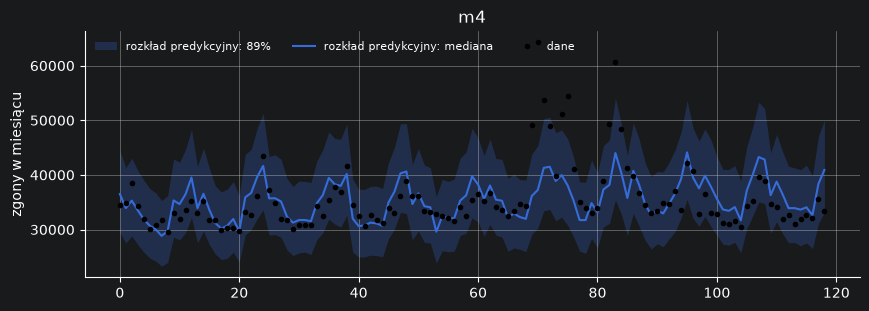

In [15]:
plot_fit(m4_data, pl_temp_a, 'm4')

## 2. Okres referencyjny i trend

Dopasuj model M4 do lat 2017–2019 zamiast 2015–2019, a także wersję z trendem kwadratowym i wersję bez trendu. Porównaj rozkłady łącznej liczby zgonów nadmiarowych w latach 2020–2022 oraz w 2023 r. i przedstaw na wykresie oczekiwaną roczną liczbę zgonów w latach 2015–2023 w każdym wariancie. Który wariant uważasz za najbardziej uzasadniony?

In [ ]:
# TODO: utwórz maski okresów treningowych oraz warianty predyktorów czasu.
# Dla porównania predykcji użyj tej samej definicji lat i agregacji we wszystkich modelach.
# TODO: dopasuj trzy warianty, przeprowadź diagnostykę i wygeneruj kontrfaktyczne prognozy.
# TODO: przygotuj rozkłady sum rocznych i wspólny wykres oczekiwanej liczby zgonów.


## 3. Zmienność międzyroczna

Dodaj do modelu M4 losowy efekt roku $u_r = \sigma_u z_r$, $z_r \sim \mathcal{N}(0, 1)$ (parametryzacja niescentrowana) dla lat 2015–2023, przy czym lata 2020–2023 nie mają danych uczących (potrzebne będą dodatkowa kolumna z indeksem roku, kontener `pm.Data` i współrzędne `year`). Jaki jest rozkład a posteriori $u_{2021}$ i dlaczego? Jak zmieniła się szerokość przedziałów dla rocznych zgonów nadmiarowych? Zwróć uwagę na rozbieżności i spróbuj je usunąć (np. zwiększając `target_accept` lub wybierając rozkład a priori $\sigma_u$, który nie dopuszcza wartości bliskich zera).

In [ ]:
# TODO: zbuduj mapę rok -> indeks 0..8 i osobny wektor indeksów obserwacji.
# W modelu zarejestruj współrzędną year obejmującą 2015–2023 i kontener pm.Data.
# TODO: dodaj z_r ~ Normal(0, 1), sigma_u oraz deterministyczne u = sigma_u * z_r.
# TODO: porównaj diagnostykę i przedziały z bazowym M4; nie ucz modelu na latach 2020–2023.


## 4. Dane tygodniowe

Plik `world_mortality.csv` zawiera dla Polski dane tygodniowe (tygodnie ISO; datę poniedziałku danego tygodnia obliczysz jak w funkcji `to_monthly`). Zbuduj dla nich model, opisując sezonowość szeregiem Fouriera $\sum_{k=1}^{K} \big(a_k \sin\tfrac{2\pi k w}{52{,}18} + b_k \cos\tfrac{2\pi k w}{52{,}18}\big)$, gdzie $w$ to numer tygodnia (wszystkie tygodnie mają 7 dni, więc ekspozycja nie jest potrzebna). Dobierz $K$ za pomocą LOO. Porównaj łączną liczbę zgonów nadmiarowych w latach 2020–2022 z wynikiem z danych miesięcznych. Czy węższy przedział wiarygodności jest uzasadniony? Sprawdź autokorelację reszt.

In [ ]:
weekly_pol = wmd.loc[(wmd["iso3c"] == "POL") & (wmd["time_unit"] == "weekly")].copy()
weekly_pol["monday"] = pd.to_datetime(
    weekly_pol["year"].astype(str) + "-W" + weekly_pol["time"].astype(str).str.zfill(2) + "-1",
    format="%G-W%V-%u",
)
weekly_pol = weekly_pol.sort_values("monday").reset_index(drop=True)

# TODO: skonstruuj numer tygodnia w czasie w sposób ciągły i przygotuj okres referencyjny.
# TODO: dla kilku K zbuduj modele Fouriera i porównaj je PSIS-LOO (te same obserwacje).
# TODO: sprawdź autokorelację reszt oraz zestaw roczne sumy z miesięcznym modelem.


## 5. Cały świat

Rozszerz model hierarchiczny na wszystkie kraje ze zbioru `world_mortality.csv`. Ponieważ dane części krajów kończą się w 2022 r. (np. Peru, Boliwia, Ukraina), wygodnie jest analizować lata 2020–2021 i dopuścić braki w okresie referencyjnym (np. wymagać co najmniej 30 miesięcy z lat 2015–2019). Uwzględnij to, że na półkuli południowej zima przypada na czerwiec–sierpień, np. przez osobne profile sezonowe `season_mu` dla obu półkul (wymiary `("hemisphere", "month")`). Do półkuli południowej można zaliczyć kraje i terytoria: ARG, AUS, BOL, BRA, BWA, CHL, FJI, MUS, MYT, NAM, NCL, NZL, PER, PRY, PYF, REU, URY, ZAF. W których krajach wskaźnik P był najwyższy, a w których ujemny? Uwaga: próbkowanie modelu dla ok. 120 krajów trwa kilka minut; jeżeli ESS hiperparametrów jest zbyt małe, zwiększ `draws` i `tune`.

In [ ]:
SOUTHERN_HEMISPHERE = {
    "ARG", "AUS", "BOL", "BRA", "BWA", "CHL", "FJI", "MUS", "MYT", "NAM",
    "NCL", "NZL", "PER", "PRY", "PYF", "REU", "URY", "ZAF",
}

# TODO: przygotuj miesięczny panel krajów i wybierz kwalifikujące się kraje
# na podstawie liczby obserwowanych miesięcy w okresie referencyjnym.
# TODO: dodaj indeksy kraju/półkuli, hierarchiczne efekty i sezonowe coords
# o wymiarach ("hemisphere", "month").
# TODO: wykonaj predykcję kontrfaktyczną dla 2020–2021 i podsumuj posterior P.


## 6. Test placebo

Szczepionki nie były dostępne w 2020 r. Powtórz analizę z rozdziału 6, przyjmując jako zmienną objaśnianą wskaźnik P za 2020 r. (kolumny `P_2020` i `P_2020_sd` tabeli `pscores`, czyli `factor_model(..., y="P_2020")`). Jakiego współczynnika przy szczepieniach należałoby oczekiwać, gdyby model F2 poprawnie usuwał zakłócenia, a jaki otrzymujesz? Co z tego wynika?

In [ ]:
# Oczekuje się, że w poprzednim zadaniu/analizie utworzono tabelę pscores
# z indeksami krajów ISO3 oraz kolumnami P_2020 i P_2020_sd.
# TODO: połącz pscores z covariates, utwórz fac_cc i dopasuj wariant F2 z y="P_2020".
# Uwaga: pozostaw ten model osobny od modelu z wynikiem P_2021_2022.
# TODO: opisz posterior współczynnika vaccinated_2021 i ograniczenia placebo.


## 7. Inne czynniki

Dodaj do modelu F2 zmienne `hospital_beds_per_thousand`, `cardiovasc_death_rate` i `stringency_2020_2021` (pojedynczo i wszystkie naraz). Jak zmieniają się współczynniki? Porównaj modele za pomocą LOO — wszystkie na tym samym zbiorze krajów i w wersji brzegowej z p. 6.3 (dlaczego wersja z ukrytymi $P_c$ nie nadaje się do PSIS-LOO?). Omów problem współliniowości.

In [ ]:
# TODO: określ jedną wspólną próbę krajów bez braków dla wszystkich porównań.
# Dopasuj F2 bazowy, trzy rozszerzenia pojedynczym predyktorem oraz rozszerzenie łączne.
# TODO: użyj brzegowej wiarygodności dla obserwowanego P i jego błędu pomiaru
# (bez dodatkowego ukrytego P_c, które utrudnia PSIS-LOO po krajach).
# TODO: porównaj az.compare na tych samych obserwacjach i oceń korelacje predyktorów.


## Podsumowanie własnej analizy

Uzupełnij po wykonaniu wybranych zadań:

- **Najważniejsze decyzje modelowe:** …
- **Diagnostyka i ograniczenia:** …
- **Wyniki, które są stabilne względem wariantów:** …
- **Pytania wymagające dalszej analizy:** …